In [3]:
import numpy as np
import matplotlib.pyplot as plt

from quantify_core.data.handling import (
    set_datadir,
    default_datadir,
    load_dataset,
)

import os
import json

In [4]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [84]:
# def process_CMAES_data_final(dataset, population_size, qubit_names=None, batched_qubit_names=None):
#     """
#     Processes fidelity data for n qubits based on the given dataset and population size.

#     Parameters:
#         dataset: An xarray-like object containing data attributes 
#                  (e.g., dataset.x0.data, dataset.y0.data, etc.).
#         population_size: The size of the population.
#         qubit_names: List of qubit names. If None, will try to use dataset.elements.
#         batched_qubit_names: Optional list of lists, grouping qubits together.

#     Returns:
#         A dictionary containing mean and population fidelity data for all qubit_names 
#         and optionally for batched_qubit_names.
#     """

#     if qubit_names is None:
#         if hasattr(dataset, "elements"):
#             qubit_names = dataset.elements
#         else:
#             raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

#     fidelity_data = {}

#     # Maps descriptive names to dataset keys
#     name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
#     name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}

#     # Handle batched qubits
#     if batched_qubit_names is not None:
#         batched_names = ["_".join(qubits) for qubits in batched_qubit_names]

#         for batched_name in batched_names:
#             obj = dataset[name_to_var.get(f"objective{batched_name}")].values
            
#             fidelity_data[batched_name] = {
#                 'objective': obj,
#                 'mean': {'objective': obj[population_size::population_size + 1]},
#                 'pop': {'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])}
#             }

#     # Handle individual qubits
#     for qubit in qubit_names:
#         # Base fidelity data
#         fidelity_data[qubit] = {
#             'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
#             'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
#             'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
#             'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
#             'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
#             'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
#             'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
#             'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
#         }

#         # Mean values
#         fidelity_data[qubit]['mean'] = {
#             key: fidelity_data[qubit][key][population_size::population_size + 1]
#             for key in ['freq', 'ampl', 'dur',
#                         'assignfid_av', 'assignfid_01', 
#                         'assignfid_02', 'assignfid_12', 'qndpifid']
#         }

#         # Population values
#         fidelity_data[qubit]['pop'] = {
#             key: np.array([
#                 fidelity_data[qubit][key][i::population_size + 1]
#                 for i in range(population_size)
#             ])
#             for key in ['freq', 'ampl', 'dur',
#                         'assignfid_av', 'assignfid_01', 
#                         'assignfid_02', 'assignfid_12', 'qndpifid']
#         }

#         if batched_qubit_names is None:
#             obj = dataset[name_to_var.get(f"objective{qubit}")].values
#             fidelity_data[qubit].update({
#                 'objective': obj
#             })
#             fidelity_data[qubit]['mean'].update({
#                 'objective': obj[population_size::population_size + 1]
#             })
#             fidelity_data[qubit]['pop'].update({
#                 'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])
#             })

#     return fidelity_data

import numpy as np

def process_CMAES_data_final(dataset, population_size, qubit_names=None, batched_qubit_names=None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An xarray-like object containing data attributes 
                 (e.g., dataset.x0.data, dataset.y0.data, etc.).
        population_size: The size of the population.
        qubit_names: List of qubit names. If None, will try to use dataset.elements.
        batched_qubit_names: Optional list of lists, grouping qubits together.

    Returns:
        A dictionary containing mean and population fidelity data for all qubit_names 
        and optionally for batched_qubit_names.
    """

    if qubit_names is None:
        if hasattr(dataset, "elements"):
            qubit_names = dataset.elements
        else:
            raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

    fidelity_data = {}

    # Maps descriptive names to dataset keys
    name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
    name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}

    # --- Handle batched qubits (if any) ---
    if batched_qubit_names is not None:
        batched_names = ["_".join(qubits) for qubits in batched_qubit_names]

        for batched_name in batched_names:
            var_key = name_to_var.get(f"objective{batched_name}")
            if var_key is None:
                continue
            obj = dataset[var_key].values

            new_entry = {
                'objective': obj,
                'mean': {'objective': obj[population_size::population_size + 1]},
                'pop': {'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])}
            }

            # ✅ If key exists, extend/update instead of overwriting
            if batched_name in fidelity_data:
                fidelity_data[batched_name]['objective'] = obj
                fidelity_data[batched_name]['mean']['objective'] = new_entry['mean']['objective']
                fidelity_data[batched_name]['pop']['objective'] = new_entry['pop']['objective']
            else:
                fidelity_data[batched_name] = new_entry

    # --- Handle individual qubits ---
    for qubit in qubit_names:
        # Initialize if not existing
        if qubit not in fidelity_data:
            fidelity_data[qubit] = {}

        # Base fidelity data
        fidelity_data[qubit].update({
            'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
            'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
            'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
            'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
            'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
            'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
            'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
            'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
        })

        # Mean values
        fidelity_data[qubit]['mean'] = fidelity_data[qubit].get('mean', {})
        fidelity_data[qubit]['mean'].update({
            key: fidelity_data[qubit][key][population_size::population_size + 1]
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        })

        # Population values
        fidelity_data[qubit]['pop'] = fidelity_data[qubit].get('pop', {})
        fidelity_data[qubit]['pop'].update({
            key: np.array([
                fidelity_data[qubit][key][i::population_size + 1]
                for i in range(population_size)
            ])
            for key in ['freq', 'ampl', 'dur',
                        'assignfid_av', 'assignfid_01', 
                        'assignfid_02', 'assignfid_12', 'qndpifid']
        })

        # If no batch entry overwrote objective, use individual one
        if f"objective{qubit}" in name_to_var and 'objective' not in fidelity_data[qubit]:
            obj = dataset[name_to_var.get(f"objective{qubit}")].values
            fidelity_data[qubit].update({
                'objective': obj
            })
            fidelity_data[qubit]['mean'].update({
                'objective': obj[population_size::population_size + 1]
            })
            fidelity_data[qubit]['pop'].update({
                'objective': np.array([obj[i::population_size + 1] for i in range(population_size)])
            })

    return fidelity_data


In [85]:
def compute_convergence(data, qubit_names, ref_freqs, batched_qubit_names = None, N_window=10, ref_ampl=0.005, ref_dur=2e-8):
    objective = 0
    norm = 0

    for i, qubit in enumerate(qubit_names):
        diff_freq = np.abs(np.diff(data[qubit]['mean']['freq']/ref_freqs[i]))
        diff_ampl = np.abs(np.diff(data[qubit]['mean']['ampl']/ref_ampl))
        diff_dur = np.abs(np.diff(data[qubit]['mean']['dur']/ref_dur))

        vector = np.array([diff_freq, diff_ampl, diff_dur]).T
        norm += np.linalg.norm(vector, axis=1)/len(qubit_names)

    for qubits in batched_qubit_names:
        key = "_".join(qubits)
        objective += data[key]['mean']['objective']/len(qubit_names)

        
    scaled_objective = -1/objective[1:]*norm
    running_av_so = np.array([np.mean(scaled_objective[i:i+N_window]) for i in range(len(scaled_objective)-N_window+1)])

    return running_av_so

In [86]:
#Warmstart
tuids = ["20251003-205912-226-fb425d","20251003-212633-261-f2cddc", "20251003-215409-821-382786", "20251003-222158-351-2c3dfc"]
nr_ws_samples = [0,30,40,50]
popsize = 20
batched_qubit_names=[['D8', 'X4']]

running_av = {}

for tuid, ws_samples in zip(tuids, nr_ws_samples):
    dataset = load_dataset(tuid)
    data = process_CMAES_data_final(dataset, popsize, batched_qubit_names=batched_qubit_names)
    running_av[f'{ws_samples}_samples'] = compute_convergence(data, dataset.elements, ref_freqs = dataset.clock_freqs, batched_qubit_names=batched_qubit_names, N_window=10)



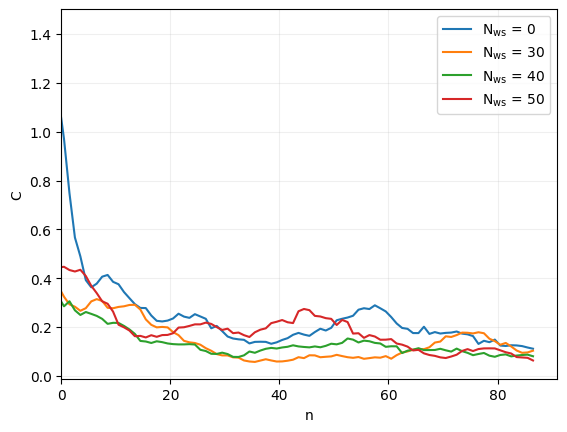

In [87]:
for key, ws_samples in zip(running_av.keys(), nr_ws_samples):
    n = np.arange(len(running_av[key]))
    plt.plot(n - (50/popsize), running_av[key], label=r'N$_\mathrm{ws}$ = ' + str(ws_samples))

plt.legend()
plt.xlabel('n')
plt.ylabel('C')
plt.grid(alpha=.2)
plt.xlim(left=0)
plt.show()

In [100]:
#Nr qubits
tuids = ["20251007-210014-684-8d930d","20251008-012236-788-1fa287", "20251008-043614-423-f638f3", "20251008-064532-492-f1cd35"]
nr_qubits_list = np.array([14,10,6,4])
runtimes = np.array([262, 194, 129, 92])
popsize = 60
batched_list =[[['D2'], ['D3'], ['D4'], ['D5'], ['D6'], ['D7'], ['D8'], ['D9'], ['X3'], ['X4'], ['Z1'], ['Z2'], ['Z3'], ['Z4']], 
              [['D2'], ['D3'], ['D4'], ['D5'], ['D6'], ['D7'], ['D8'], ['D9'], ['X3'], ['X4']], 
              [['D2'], ['D3'], ['D4'], ['D5'], ['D6'], ['D7']],
              [['D2'], ['D3'], ['D4'], ['D5'] ]
              ]

running_av = {}

for tuid, ws_samples, batched_qubit_names in zip(tuids, nr_ws_samples, batched_list):
    dataset = load_dataset(tuid)
    data = process_CMAES_data_final(dataset, popsize, batched_qubit_names=batched_qubit_names)
    running_av[f'{ws_samples}_samples'] = compute_convergence(data, dataset.elements, ref_freqs = dataset.clock_freqs, batched_qubit_names=batched_qubit_names, N_window=10)


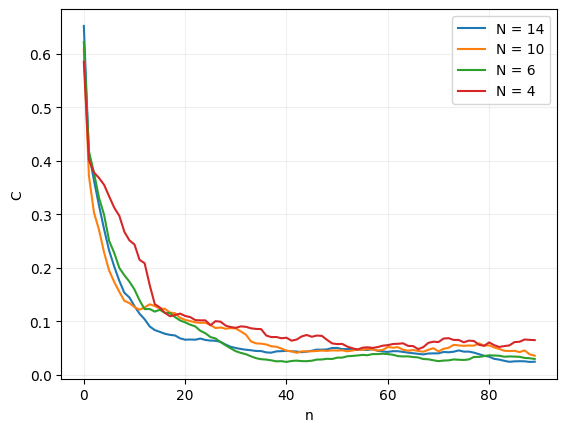

In [101]:
for key, nr_qubits in zip(running_av.keys(), nr_qubits_list):
    n = np.arange(len(running_av[key]))
    plt.plot(n, running_av[key], label=r'N = ' + str(nr_qubits))

plt.legend()
plt.xlabel('n')
plt.ylabel('C')
plt.grid(alpha=.2)
plt.show()

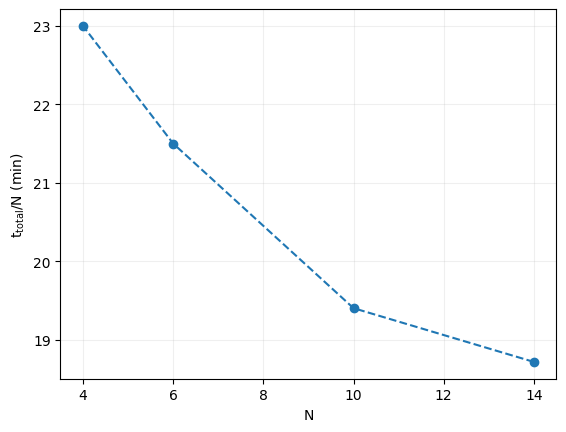

In [112]:
fig, ax = plt.subplots()

ax.plot(nr_qubits_list, runtimes/nr_qubits_list, "o", ls='dashed')
ax.set_xlabel("N")
ax.set_ylabel(r"$\mathrm{t_{total}/N}$ (min)")
ax.grid(alpha=.2)
plt.show()